# 02 · Two-stage detector: Faster R-CNN (ResNet-50 FPN v2)

All runs share the protocol of the other notebooks: fold 0 held out, 12 epochs, 1344 px input, scored with our COCO evaluator (ignored regions as crowd, `maxDets=[1,100,500]`).

* `frcnn_base` – torchvision defaults (anchors 32-512).
* `frcnn_a16` – anchors **16-256** (EDA: default anchors reach IoU ≥ 0.5 with only 75% of boxes, these reach 98%).
* `frcnn_giou` – RoI box loss replaced by **GIoU** and 2000 test proposals instead of 1000.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve() / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from hw2 import CLASSES
from hw2.analysis import load_run, metrics_table, curve, error_breakdown, worst_frames, draw
from hw2.data import find_data_root, fold_frames, load_all, make_folds, subsample

sns.set_theme(style="whitegrid", context="notebook")
IMG = Path("../images"); IMG.mkdir(exist_ok=True)
frames, boxes = load_all(find_data_root())
val = subsample(fold_frames(frames, make_folds(frames), 0), 4)   # the validation frames every run was scored on
vpath = val.set_index("key").path
vboxes = boxes[boxes.key.isin(set(val.key))]


In [2]:
def table(runs):
    return metrics_table(runs).round(4)

def per_class(runs):
    rows = {r: {c: json.load(open(f"../runs/{r}/metrics.json"))[f"AP_{c}"] for c in CLASSES} for r in runs}
    return pd.DataFrame(rows).T.round(3)

def plot_curves(runs, title, fname, x="epoch"):
    fig, ax = plt.subplots(figsize=(7, 4))
    for r in runs:
        c = curve(load_run(r))
        ax.plot(c[x], c.mAP, marker="o", ms=4, label=r)
    ax.set_xlabel(x if x == "epoch" else "training time, min"); ax.set_ylabel("mAP@[.5:.95] on fold 0"); ax.set_title(title); ax.legend()
    fig.tight_layout(); fig.savefig(IMG / fname, dpi=140); plt.show()

def breakdown(runs, thr=0.3):
    rows = {}
    for r in runs:
        p = load_run(r)["val_preds"]
        rows[r] = error_breakdown(p, vboxes, val.key, score_thr=thr)
    return pd.DataFrame(rows).T

def crop_window(gt, W, H, frac=0.45):
    """The (frac*W x frac*H) window that holds the most ground-truth centres."""
    g = gt[gt.ignore == 0]
    cx, cy = g.x + g.w / 2, g.y + g.h / 2
    w, h = int(W * frac), int(H * frac)
    best = max(((x0, y0) for x0 in np.linspace(0, W - w, 4).astype(int) for y0 in np.linspace(0, H - h, 4).astype(int)),
               key=lambda p: ((cx >= p[0]) & (cx < p[0] + w) & (cy >= p[1]) & (cy < p[1] + h)).sum())
    return best[0], best[1], best[0] + w, best[1] + h

def show_cases(runs, cases, fname, thr=0.3):
    """One row per failure case, one column per run: green = ground truth, grey = ignored region, red = detections."""
    fig, axes = plt.subplots(len(cases), len(runs), figsize=(6.5 * len(runs), 4.2 * len(cases)), squeeze=False)
    preds = {r: load_run(r)["val_preds"] for r in runs}
    for i, (key, why) in enumerate(cases):
        gt = vboxes[vboxes.key == key]
        fr = val.set_index("key").loc[key]
        crop = crop_window(gt, int(fr.width), int(fr.height))
        for j, r in enumerate(runs):
            axes[i, j].imshow(draw(vpath[key], preds[r][preds[r].key == key], gt, thr, crop))
            axes[i, j].set_title(f"{r}: {why}", fontsize=9); axes[i, j].axis("off")
    fig.tight_layout(); fig.savefig(IMG / fname, dpi=120); plt.show()

def pick_cases(run, n_sample=150):
    """Three failure types for one run: missed small objects, class confusions, false alarms."""
    p = load_run(run)["val_preds"]
    w = worst_frames(p, vboxes, val.key, n_sample=n_sample)
    miss = w.sort_values("missed_small", ascending=False).index[0]
    conf = w[w.index != miss].sort_values("cls", ascending=False).index[0]
    fp = w[~w.index.isin([miss, conf])].sort_values("background", ascending=False).index[0]
    return w, [(miss, "most missed small objects"), (conf, "most class confusions"), (fp, "most background false alarms")]


## Metrics

In [3]:
R = ['frcnn_base', 'frcnn_a16', 'frcnn_giou']
table(R)

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,fps,train_min
run,,,,,,,,,
frcnn_base,0.2595,0.4813,0.2458,0.0811,0.1874,0.4422,0.4365,14.37,105.8
frcnn_a16,0.2736,0.5149,0.2538,0.0802,0.2036,0.4610,0.4497,14.35,106.9
frcnn_giou,0.2608,0.4849,0.2431,0.0778,0.1820,0.4424,0.4540,10.90,114.3


In [4]:
per_class(R)

,person,bicycle,car,van,truck,tricycle,bus,motor
frcnn_base,0.215,0.071,0.480,0.218,0.137,0.319,0.512,0.124
frcnn_a16,0.220,0.079,0.481,0.220,0.200,0.300,0.560,0.134
frcnn_giou,0.216,0.069,0.480,0.221,0.178,0.284,0.517,0.122


## Training curves

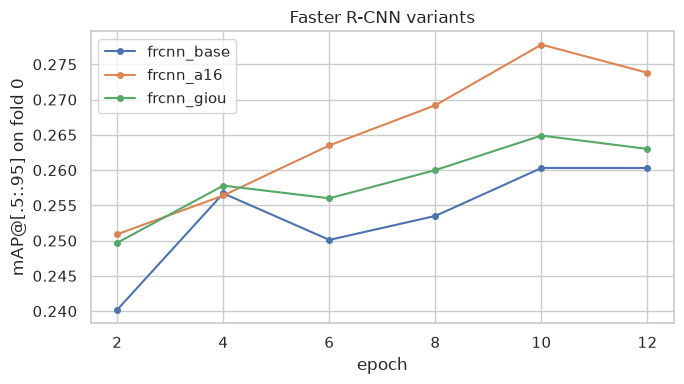

,epoch,loss_classifier,loss_box_reg,loss_objectness,loss_rpn_box_reg
0,1,0.443,0.467,0.127,0.114
1,2,0.262,0.384,0.052,0.092
2,3,0.228,0.360,0.040,0.084
3,4,0.210,0.343,0.034,0.077
4,5,0.194,0.331,0.030,0.073
5,6,0.182,0.319,0.027,0.070
6,7,0.175,0.309,0.024,0.066
7,8,0.164,0.300,0.022,0.063
8,9,0.158,0.292,0.020,0.061
9,10,0.155,0.286,0.019,0.059


In [5]:
plot_curves(R, 'Faster R-CNN variants', 'curve_frcnn.png')
h = pd.read_csv('../runs/frcnn_base/history.csv')
h[['epoch','loss_classifier','loss_box_reg','loss_objectness','loss_rpn_box_reg']].round(3)

## Where the errors are

Detections with score ≥ 0.3 are labelled true positive / duplicate / wrong class / badly localised / inside an ignored region / background; ground-truth objects with no matching detection are counted as missed by COCO size.

In [6]:
bd = breakdown(R); bd

,tp,duplicate,cls,loc,ignored,background,missed_small,missed_medium,missed_large,recall_small,recall_medium,recall_large
frcnn_base,44840.0,425.0,5981.0,4747.0,10925.0,7563.0,8197.0,14373.0,1121.0,0.353,0.679,0.898
frcnn_a16,44361.0,369.0,5864.0,4701.0,13200.0,8071.0,8295.0,14705.0,1170.0,0.345,0.672,0.894
frcnn_giou,45864.0,642.0,6642.0,5672.0,15660.0,9407.0,7929.0,13541.0,1197.0,0.374,0.698,0.892


In [7]:
bd[['tp','duplicate','cls','loc','ignored','background']].div(bd.tp, axis=0).round(2).T

,frcnn_base,frcnn_a16,frcnn_giou
tp,1.00,1.00,1.00
duplicate,0.01,0.01,0.01
cls,0.13,0.13,0.14
loc,0.11,0.11,0.12
ignored,0.24,0.30,0.34
background,0.17,0.18,0.21


## Failure cases (3)

Chosen automatically from a random sample of 150 validation frames.

[('uav0000124_00944_v_0000165', 'most missed small objects'), ('uav0000288_00001_v_0000033', 'most class confusions'), ('uav0000140_01590_v_0000189', 'most background false alarms')]


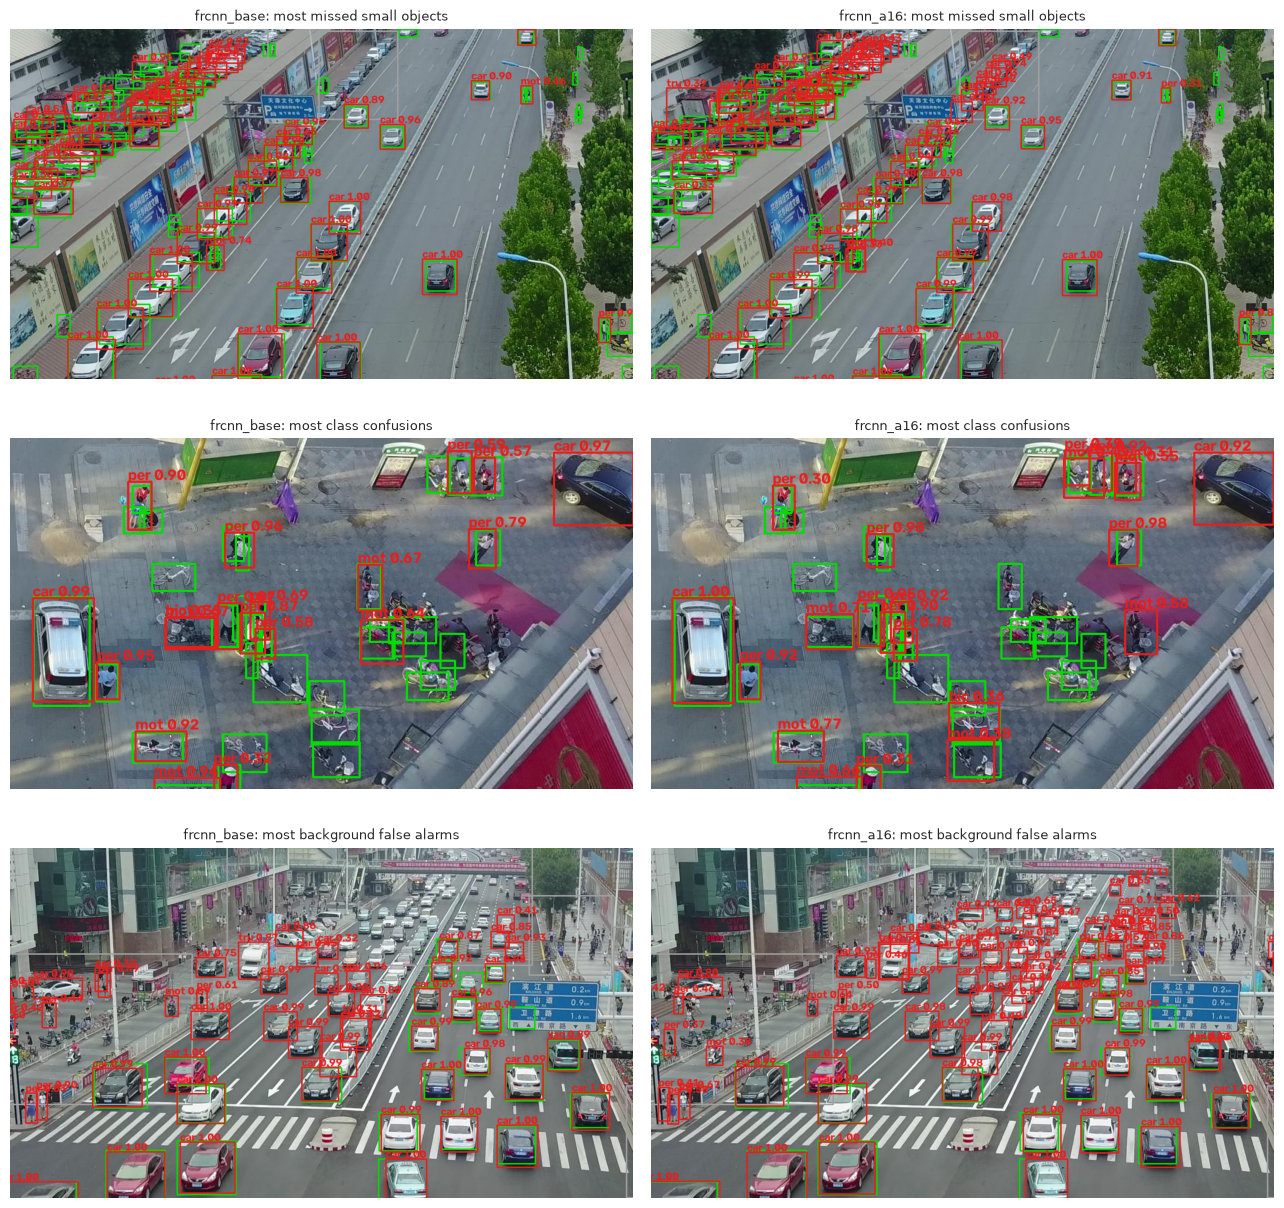

In [8]:
w, cases = pick_cases('frcnn_base')
print(cases)
show_cases(['frcnn_base', 'frcnn_a16'], cases, 'fail_frcnn.png')

In [9]:
w.loc[[c[0] for c in cases]].T

key,uav0000124_00944_v_0000165,uav0000288_00001_v_0000033,uav0000140_01590_v_0000189
tp,72.000,37.000,40.000
duplicate,0.000,0.000,0.000
cls,0.000,19.000,1.000
loc,8.000,2.000,3.000
ignored,3.000,0.000,53.000
background,2.000,9.000,27.000
missed_small,29.000,6.000,0.000
missed_medium,31.000,37.000,3.000
missed_large,0.000,0.000,0.000
recall_small,0.065,0.625,1.000
